In [58]:
import sys
import time
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve()))  # para poder importar som/
from som import SOM

In [59]:
def generar_datos(n, seed):
    return np.random.default_rng(seed).integers(0, 256, (n, 3)) / 255

# Conjunto de prueba fijo, con otra semilla, que ningún modelo ve al entrenar
test = generar_datos(500, seed=999)

In [60]:
rejilla = {
    "lado":      [10, 30, 50],
    "periodo":   [2000, 5000, 10000],
    "lr":        [0.001, 0.01, 0.05, 0.1, 0.4],
    "num_datos": [100, 500],
}

resultados = []
modelos = {}
combinaciones = list(itertools.product(*rejilla.values()))

for n, (lado, periodo, lr, num_datos) in enumerate(combinaciones, 1):
    datos_train = generar_datos(num_datos, seed=42)
    som_k = SOM(lado=lado, seed=42)
    t = time.time()
    for _ in som_k.entrenar(datos_train, periodo, lr, cada=periodo):
        pass  # no necesitamos los pasos intermedios
    clave = (lado, periodo, lr, num_datos)
    modelos[clave] = som_k
    resultados.append({
        "lado": lado, "periodo": periodo, "lr": lr, "num_datos": num_datos,
        "err_cuant": som_k.error_cuantificacion(test),
        "err_topo": som_k.error_topologico(test),
        "segundos": round(time.time() - t, 1),
    })
    print(f"{n}/{len(combinaciones)} {clave} listo")

df = pd.DataFrame(resultados)

1/90 (10, 2000, 0.001, 100) listo
2/90 (10, 2000, 0.001, 500) listo
3/90 (10, 2000, 0.01, 100) listo
4/90 (10, 2000, 0.01, 500) listo
5/90 (10, 2000, 0.05, 100) listo
6/90 (10, 2000, 0.05, 500) listo
7/90 (10, 2000, 0.1, 100) listo
8/90 (10, 2000, 0.1, 500) listo
9/90 (10, 2000, 0.4, 100) listo
10/90 (10, 2000, 0.4, 500) listo
11/90 (10, 5000, 0.001, 100) listo
12/90 (10, 5000, 0.001, 500) listo
13/90 (10, 5000, 0.01, 100) listo
14/90 (10, 5000, 0.01, 500) listo
15/90 (10, 5000, 0.05, 100) listo
16/90 (10, 5000, 0.05, 500) listo
17/90 (10, 5000, 0.1, 100) listo
18/90 (10, 5000, 0.1, 500) listo
19/90 (10, 5000, 0.4, 100) listo
20/90 (10, 5000, 0.4, 500) listo
21/90 (10, 10000, 0.001, 100) listo
22/90 (10, 10000, 0.001, 500) listo
23/90 (10, 10000, 0.01, 100) listo
24/90 (10, 10000, 0.01, 500) listo
25/90 (10, 10000, 0.05, 100) listo
26/90 (10, 10000, 0.05, 500) listo
27/90 (10, 10000, 0.1, 100) listo
28/90 (10, 10000, 0.1, 500) listo
29/90 (10, 10000, 0.4, 100) listo
30/90 (10, 10000, 0

In [61]:
# Un mapa más grande casi siempre baja el error de cuantificación (tiene más neuronas),
# así que no basta con ordenar por eso. Criterio: buena topología primero.
buenos = df[df["err_topo"] <= 0.05].sort_values("err_cuant")
print(f"{len(buenos)} de {len(df)} modelos con error topológico <= 0.05")
buenos.head(10)

51 de 90 modelos con error topológico <= 0.05


,lado,periodo,lr,num_datos,err_cuant,err_topo,segundos
89,50,10000,0.40,500,0.080692,0.022,2.1
59,30,10000,0.40,500,0.085780,0.032,1.1
79,50,5000,0.40,500,0.087759,0.046,1.2
49,30,5000,0.40,500,0.097409,0.044,0.6
87,50,10000,0.10,500,0.099198,0.032,2.1
88,50,10000,0.40,100,0.102285,0.050,2.1
57,30,10000,0.10,500,0.106328,0.008,1.1
78,50,5000,0.40,100,0.108543,0.038,1.1
85,50,10000,0.05,500,0.111204,0.016,2.1
68,50,2000,0.40,100,0.118158,0.046,0.5


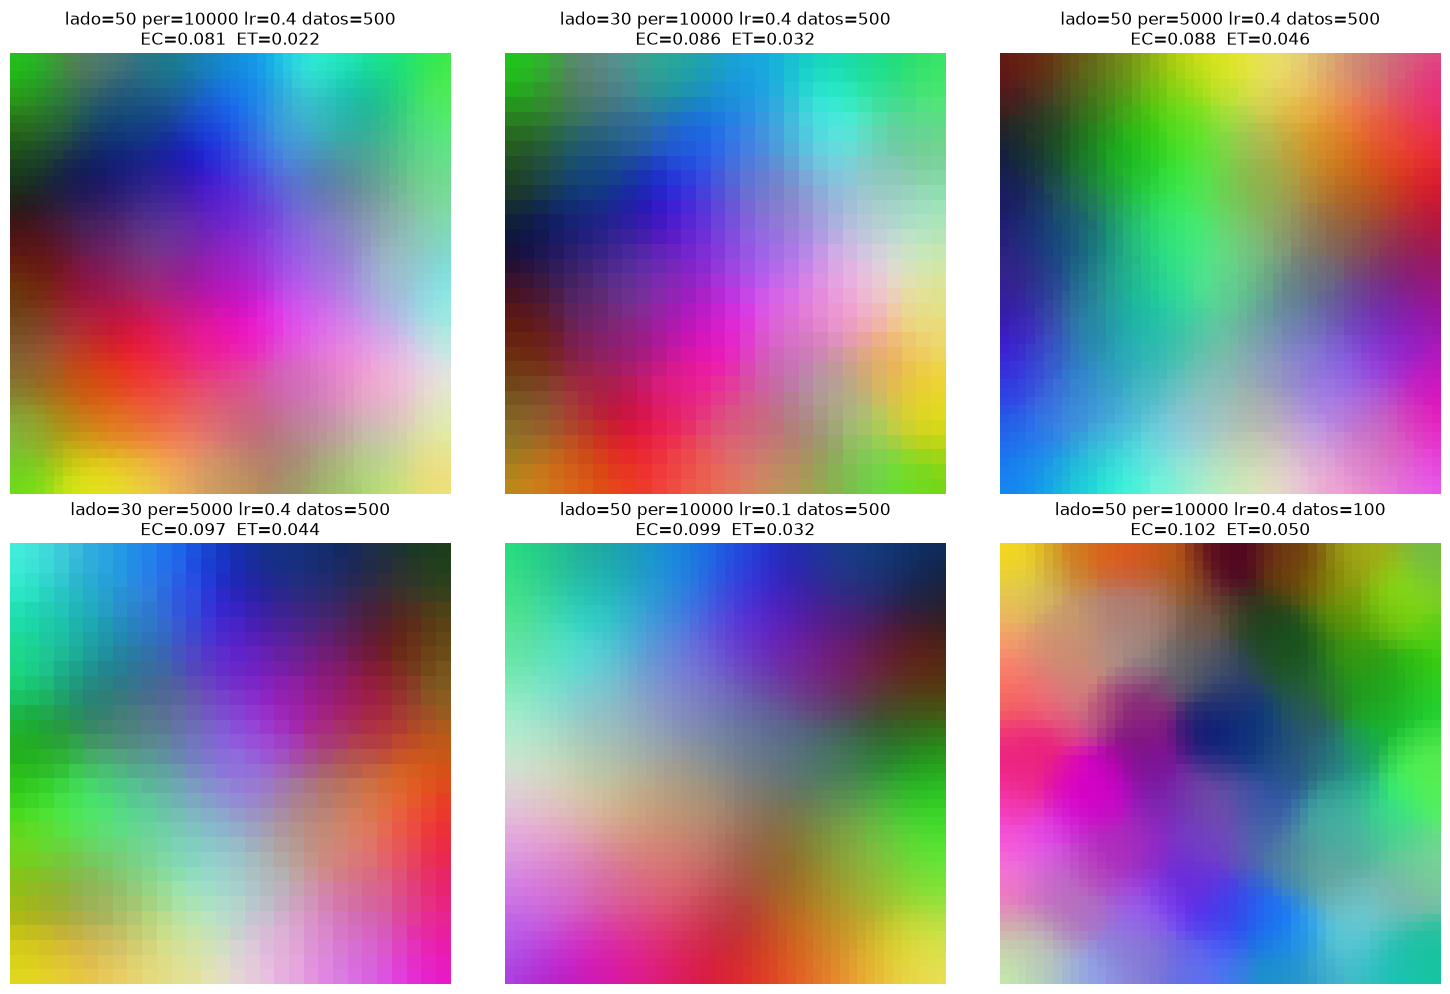

In [62]:
top = buenos.head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (_, fila) in zip(axes.ravel(), top.iterrows()):
    clave = (int(fila.lado), int(fila.periodo), fila.lr, int(fila.num_datos))
    ax.imshow(modelos[clave].pesos)
    ax.set_title(f"lado={clave[0]} per={clave[1]} lr={clave[2]} datos={clave[3]}\n"
                 f"EC={fila.err_cuant:.3f}  ET={fila.err_topo:.3f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

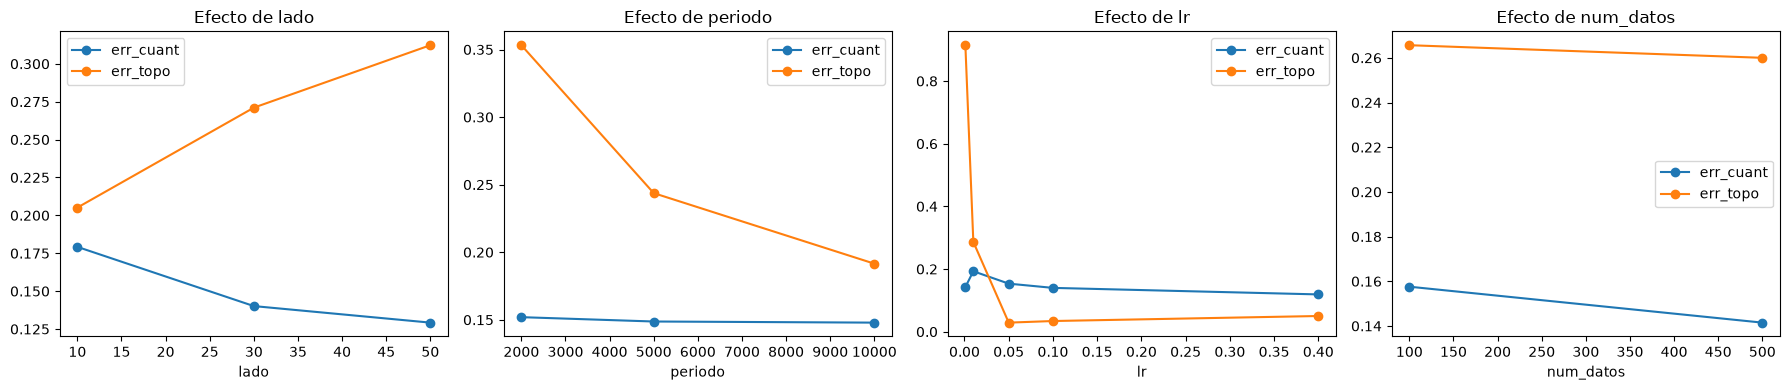

In [63]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, param in zip(axes, ["lado", "periodo", "lr", "num_datos"]):
    df.groupby(param)[["err_cuant", "err_topo"]].mean().plot(ax=ax, marker="o")
    ax.set_title(f"Efecto de {param}")
plt.tight_layout()
plt.show()

In [64]:
#elegido = (50, 10000, 0.1, 500)   # ← pon aquí la combinación que te guste
#modelos[elegido].guardar("../models/pretrained.npz")
#print("Guardado:", elegido)

In [65]:
script = SOM.cargar("../models/pretrained.npz")
print(np.allclose(script.pesos, modelos[(50, 10000, 0.1, 500)].pesos))

True
